# Know your data

### How much has the world warmed?

We asked two AI agents to make one chart
and one sentence for a slide, from the same file:

| | model | its sentence |
|---|---|---|
| A | gpt-oss-120b | *"The global land temperature has risen by **14.69 °C** between 1743 and 2013."* |
| B | GLM-5.3-Flash | *"Land temperatures in the last decade (2004–2013) were **1.4 °C** warmer than the pre-industrial average (1850–1900)."* |

Anyone can see straight away that A is nonsense. B looks right, and its headline number
is right. This notebook goes through both, from the obvious problem to the subtle ones:

| | layer | question | who catches it |
|---|---|---|---|
| 1 | **Sanity** | *Is this number even possible?* | anyone in this room |
| 2 | **What is in a "year"?** | *Which months, which countries?* | anyone who looks |
| 3 | **Method** | *Anomalies, baselines, what one row weighs* | someone who knows the method |
| 4 | **Domain** | *Land or globe? Which version? Until when?* | **someone who knows the field** |

---
## 0 · Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.width", 120)
pd.set_option("display.max_rows", 60)

# Colour-blind-safe palette.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, MUTED, GRID, FAINT = "#0b0b0b", "#52514e", "#e6e5e1", "#c9c8c4"

plt.rcParams.update({
    "figure.figsize": (10, 5.5), "figure.dpi": 110, "font.size": 11,
    "axes.titlesize": 13, "axes.labelcolor": MUTED, "axes.edgecolor": GRID,
    "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "legend.frameon": False,
})


def style(ax, title=None, subtitle=None, ylabel=None):
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if title:
        ax.set_title(title, loc="left", pad=22 if subtitle else 10)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=10, color=MUTED, va="bottom")
    if ylabel:
        ax.set_ylabel(ylabel)
    return ax


# Works from the course repo (notebooks/) and from a demo folder with data/.
DATA = next(p for p in [Path("../data"), Path("data")] if (p / "GlobalLandTemperaturesByCountry.csv").exists())


def warming(yearly, base=(1850, 1900), recent=(2003, 2012)):
    """Mean of the recent window minus mean of the base window (annual series)."""
    return yearly.loc[recent[0]:recent[1]].mean() - yearly.loc[base[0]:base[1]].mean()


def read_berkeley_txt(path):
    """Monthly tables from a Berkeley Earth .txt file -> list of (year, month, anomaly) frames."""
    tables, rows = [], []
    for line in open(path, encoding="utf-8", errors="replace"):
        if line.startswith("%") or not line.strip():
            if rows and line.startswith("%"):
                tables.append(rows)
                rows = []
            continue
        p = line.split()
        if len(p) >= 3 and p[2] != "NaN":
            rows.append((int(p[0]), int(p[1]), float(p[2])))
    if rows:
        tables.append(rows)
    return [pd.DataFrame(t, columns=["year", "month", "anomaly"]) for t in tables if len(t) > 100]

---
## 1 · What is in this file?

Before *"is the analysis right"*, ask **"what is this file?"**

In [2]:
raw = pd.read_csv(DATA / "GlobalLandTemperaturesByCountry.csv", parse_dates=["dt"])
raw["year"] = raw["dt"].dt.year
raw["month"] = raw["dt"].dt.month

print("rows        :", len(raw))
print("columns     :", list(raw.columns[:4]))
print("first / last:", raw["dt"].min().date(), "/", raw["dt"].max().date())
print("'countries' :", raw["Country"].nunique())
print("missing temperatures:", raw["AverageTemperature"].isna().sum())

rows        : 577462
columns     : ['dt', 'AverageTemperature', 'AverageTemperatureUncertainty', 'Country']
first / last: 1743-11-01 / 2013-09-01
'countries' : 243
missing temperatures: 32651


243 "countries". Are they all countries?

In [3]:
REGIONS = ["Africa", "Asia", "Europe", "North America", "South America", "Oceania", "Antarctica"]
not_countries = [c for c in sorted(raw["Country"].unique()) if c in REGIONS or "(Europe)" in c]
print("not countries:", not_countries)
print()
print("Denmark vs Denmark (Europe), mean temperature 1951-1980:")
print(raw[raw["Country"].isin(["Denmark", "Denmark (Europe)"]) & raw["year"].between(1951, 1980)]
      .groupby("Country")["AverageTemperature"].mean().round(1).to_string())
print()
print("Antarctica, rows with a temperature:", raw.loc[raw["Country"] == "Antarctica", "AverageTemperature"].notna().sum())

not countries: ['Africa', 'Antarctica', 'Asia', 'Denmark (Europe)', 'Europe', 'France (Europe)', 'Netherlands (Europe)', 'North America', 'Oceania', 'South America', 'United Kingdom (Europe)']

Denmark vs Denmark (Europe), mean temperature 1951-1980:
Country
Denmark            -17.8
Denmark (Europe)     7.9

Antarctica, rows with a temperature: 0


Continents sit in the same column as countries. `Denmark` includes Greenland and is
about 26 °C colder than `Denmark (Europe)`. And Antarctica is listed but has **no data
at all**. None of this is an error by Berkeley Earth; it is documented. But a
`groupby("Country")` treats every one of these names as one more country.

### Does every year contain the same things?

year
1743     50
1750     50
1800     65
1825    132
1850    185
1900    237
1950    242
2012    242
2013    242


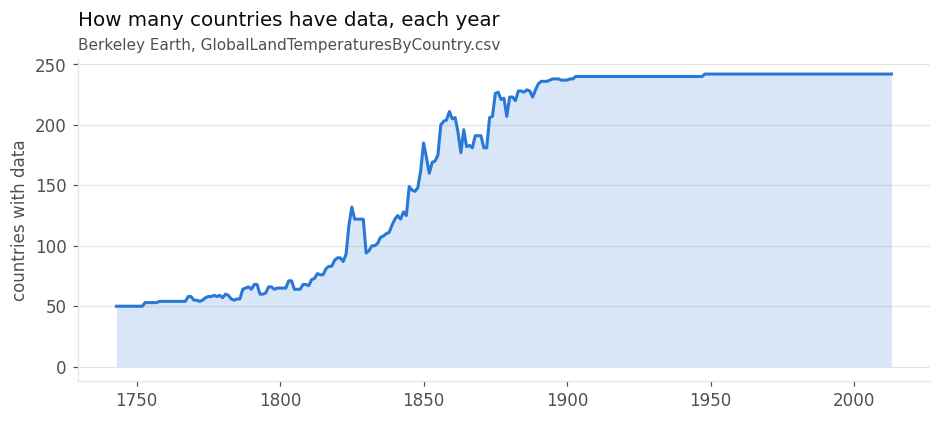

In [4]:
d = raw.dropna(subset=["AverageTemperature"])
coverage = d.groupby("year")["Country"].nunique()
print(coverage.loc[[1743, 1750, 1800, 1825, 1850, 1900, 1950, 2012, 2013]].to_string())

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(coverage.index, coverage.values, color=BLUE, alpha=0.18, linewidth=0)
ax.plot(coverage.index, coverage.values, color=BLUE, linewidth=2)
style(ax, "How many countries have data, each year", "Berkeley Earth, GlobalLandTemperaturesByCountry.csv",
      "countries with data")
plt.show()

**50 countries in 1750, 237 by 1900.** The early ones are mostly European. Any
average over "all countries" compares Europe in the 18th century with the whole
world in the 20th. Keep this chart in mind.

---
## 2 · Agent A: "+14.69 °C"

This is the line gpt-oss wrote.

In [5]:
# Compute yearly global average (average across all countries for each year)
yearly = d.groupby("year")["AverageTemperature"].mean()

first, last = yearly.index[0], yearly.index[-1]
print(f"{yearly.iloc[-1] - yearly.iloc[0]:.2f} °C between {first} and {last}")

14.69 °C between 1743 and 2013


Read the comment: *"average across all countries"*. Now read the chart title it
produced: *"Global Land Average Temperature"*. An average of countries, where Monaco
counts as much as Russia and the list changes every year, is not the global land
average. It knew what it computed, and labelled it as something else.

### What is "1743"? What is "2013"?

In [6]:
def what_is_a_year(y):
    s = d[d["year"] == y]
    return pd.Series({"months": len(s["month"].unique()),
                      "which months": ",".join(map(str, sorted(s["month"].unique()))),
                      "countries": s["Country"].nunique(),
                      "mean °C": round(s["AverageTemperature"].mean(), 2)}, name=y)

pd.DataFrame([what_is_a_year(y) for y in [1743, 1744, 1745, 1850, 2012, 2013]])

,months,which months,countries,mean °C
1743,1,11,50,5.18
1744,8,"4,5,6,7,9,10,11,12",50,9.84
1745,4,"1,2,3,4",50,1.39
1850,12,"1,2,3,4,5,6,7,8,9,10,11,12",185,16.86
2012,12,"1,2,3,4,5,6,7,8,9,10,11,12",242,19.47
2013,9,"1,2,3,4,5,6,7,8,9",242,19.88


**"1743" is one November in 50 mostly European countries. "2013" is January to
September in 242.** The headline compares a European November with nine months of
242 countries. The code takes `iloc[0]` and `iloc[-1]` without asking what they
contain.

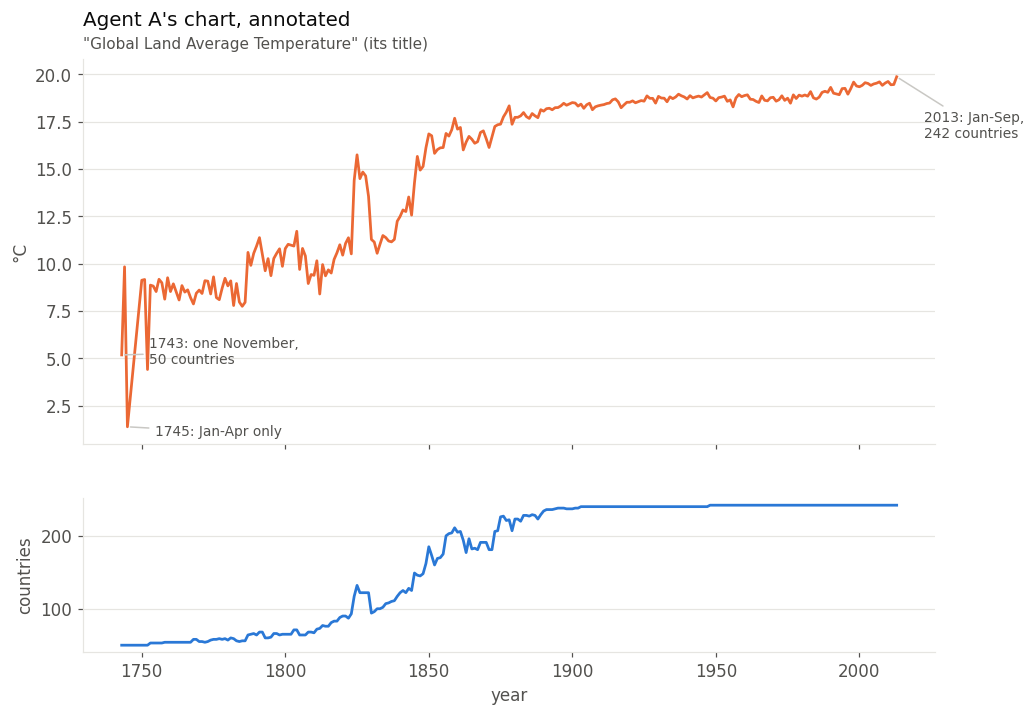

In [7]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
ax.plot(yearly.index, yearly.values, color=ORANGE, linewidth=1.8)
notes = {1743: "1743: one November,\n50 countries", 1745: "1745: Jan-Apr only",
         2013: "2013: Jan-Sep,\n242 countries"}
for y, text in notes.items():
    ax.annotate(text, (y, yearly[y]), xytext=(18, -6 if y != 2013 else -40), textcoords="offset points",
                fontsize=9, color=MUTED, arrowprops=dict(arrowstyle="-", color=FAINT))
style(ax, "Agent A's chart, annotated", '"Global Land Average Temperature" (its title)', "°C")
ax2.plot(coverage.index, coverage.values, color=BLUE, linewidth=1.8)
style(ax2, ylabel="countries")
ax2.set_xlabel("year")
plt.show()

Every step up in the orange line around 1800, 1825 and 1850 lines up with a step in
the blue one. **Those are countries joining the record, mostly warmer ones, not the
climate changing.**

Even if we only start in 1850, which feels safe, the same average still mixes in
countries that join later:

In [8]:
print(f"raw country average, 2003-2012 vs 1850-1900: {warming(yearly):+.2f} °C")
print(f"countries with data: {coverage[1850]} in 1850, {coverage[1900]} in 1900, {coverage[2012]} in 2012")

raw country average, 2003-2012 vs 1850-1900: +2.15 °C
countries with data: 185 in 1850, 237 in 1900, 242 in 2012


About +2 °C: no longer absurd, just wrong. That version could end up on a slide.

---
## 3 · Agent B: "+1.4 °C"

GLM did the textbook thing: compare each country with **its own** 1951–1980 average
(an *anomaly*), so it no longer matters which countries are warm or cold, only how
much each one changed. It even explained why in its reply. Here is its method,
reproduced:

In [9]:
base = d[d["year"].between(1951, 1980)]
counts = base.groupby("Country").size()
solid = counts[counts >= 200].index                    # "all 242 qualify"
annual_base = base[base["Country"].isin(solid)].groupby("Country")["AverageTemperature"].mean()

b1 = d[d["Country"].isin(solid)].copy()
b1["anomaly"] = b1["AverageTemperature"] - b1["Country"].map(annual_base)
glm_v1 = b1.groupby("year")["anomaly"].mean()

print(f"GLM, 2004-2013 vs 1850-1900: {warming(glm_v1, recent=(2004, 2013)):+.2f} °C")

GLM, 2004-2013 vs 1850-1900: +1.36 °C


And Berkeley Earth's own land series (a different file, from the same release) says:

In [10]:
official = pd.read_csv(DATA / "reference/kaggle_v2/GlobalTemperatures.csv", parse_dates=["dt"])
official["year"] = official["dt"].dt.year
official_land = official.groupby("year")["LandAverageTemperature"].mean()
official_lo = official.dropna(subset=["LandAndOceanAverageTemperature"]).groupby("year")["LandAndOceanAverageTemperature"].mean()

print(f"Berkeley Earth land, 2004-2013 vs 1850-1900: {warming(official_land, recent=(2004, 2013)):+.2f} °C")

Berkeley Earth land, 2004-2013 vs 1850-1900: +1.42 °C


1.36 against 1.42: **the headline is right.** It also told us the result was
*"consistent with published land-only warming estimates, so it's safe to put under
the chart."*

Let's look at the rest of what it did.

### 3a · The record year that wasn't

Its chart ends with a sharp spike in 2013.

In [11]:
clim = base.groupby(["Country", "month"])["AverageTemperature"].mean().rename("clim")
b2 = d[d["Country"].isin(solid)].join(clim, on=["Country", "month"])
b2["anomaly"] = b2["AverageTemperature"] - b2["clim"]
monthly_base = b2.groupby("year")["anomaly"].mean()

pd.DataFrame({"one baseline per country (GLM)": glm_v1, "one baseline per country AND month": monthly_base}
             ).loc[2009:2013].round(2)

,one baseline per country (GLM),one baseline per country AND month
year,,
2009,0.82,0.82
2010,0.90,0.90
2011,0.73,0.73
2012,0.74,0.74
2013,1.12,0.81


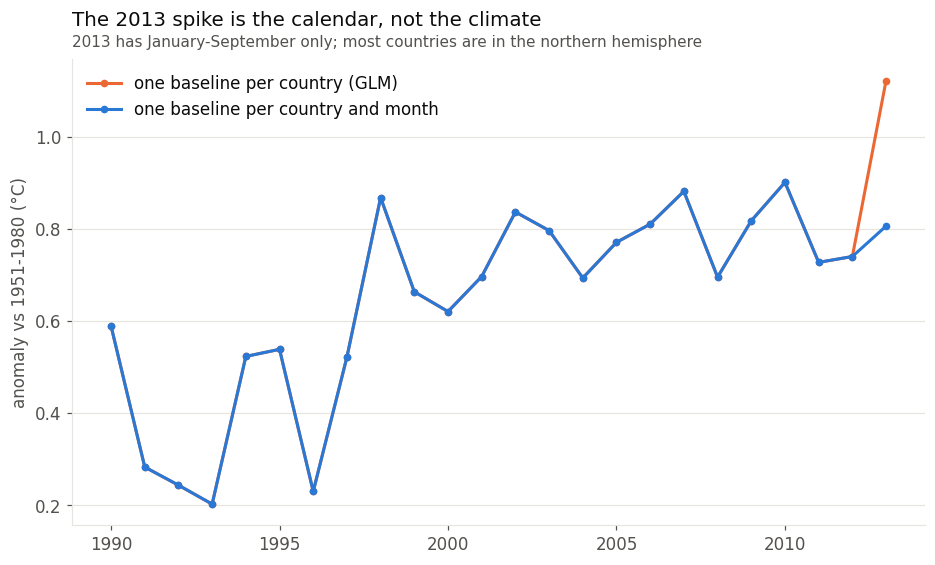

In [12]:
fig, ax = plt.subplots()
ax.plot(glm_v1.loc[1990:].index, glm_v1.loc[1990:], color=ORANGE, linewidth=2, marker="o", markersize=4,
        label="one baseline per country (GLM)")
ax.plot(monthly_base.loc[1990:].index, monthly_base.loc[1990:], color=BLUE, linewidth=2, marker="o", markersize=4,
        label="one baseline per country and month")
ax.legend(loc="upper left")
style(ax, "The 2013 spike is the calendar, not the climate",
      "2013 has January-September only; most countries are in the northern hemisphere", "anomaly vs 1951-1980 (°C)")
plt.show()

2013 only has January to September. GLM compared every month with the country's
**annual** average, so a year that is missing October to December (cold months for
most countries) looks warmer than it was. With one baseline per *calendar month*,
the seasonal cycle cancels and the "record" disappears.

The headline barely moves, but **the last point on the chart is the one people look at.**

### 3b · "All 242 qualify"

In [13]:
in_solid = [c for c in solid if c in not_countries]
print("in GLM's 242 'countries':", in_solid)

no_regions = b2[~b2["Country"].isin(not_countries)]
fixed = no_regions[no_regions["year"] <= 2012].groupby("year")["anomaly"].mean()
print()
print(f"with regions   : {warming(monthly_base.loc[:2012]):+.3f} °C")
print(f"countries only : {warming(fixed):+.3f} °C")

in GLM's 242 'countries': ['Africa', 'Asia', 'Denmark (Europe)', 'Europe', 'France (Europe)', 'Netherlands (Europe)', 'North America', 'Oceania', 'South America', 'United Kingdom (Europe)']

with regions   : +1.326 °C
countries only : +1.325 °C


Ten of the 242 are continents or duplicates. Removing them changes the result by
**a thousandth of a degree**.

After we pointed this out, GLM fixed it and explained: *"The corrections moved the
figure from 1.4 → 1.3 °C (the continent rows and partial-year spike were both
inflating it slightly)."* **The first half of that explanation is false.** The fix
was correct; the story about why the number changed was made up. The real change,
1.36 → 1.32, came from dropping the partial year and moving the window one year. It
reported it as "1.4 → 1.3", which makes a 0.04 °C change look like a 0.1 °C one.

### 3c · One country, one vote

After all the fixes, the agent's answer is 1.3 °C. Berkeley Earth's own land series
says 1.4. **The fixed number is further from the reference than the broken one.**

In [14]:
ref = official_land - official_land.loc[1951:1980].mean()
ours = fixed - fixed.loc[1951:1980].mean()

print(f"average of countries (all fixes) : {warming(ours):+.2f} °C")
print(f"Berkeley Earth land (area-based) : {warming(ref):+.2f} °C")

small = ["Monaco", "Liechtenstein", "San Marino", "Andorra", "Luxembourg", "Malta"]
print("\nsome countries that count exactly as much as Russia, Canada or Brazil:")
print([c for c in small if c in set(d["Country"])])

average of countries (all fixes) : +1.32 °C
Berkeley Earth land (area-based) : +1.41 °C

some countries that count exactly as much as Russia, Canada or Brazil:
['Monaco', 'Liechtenstein', 'San Marino', 'Andorra', 'Luxembourg', 'Malta']


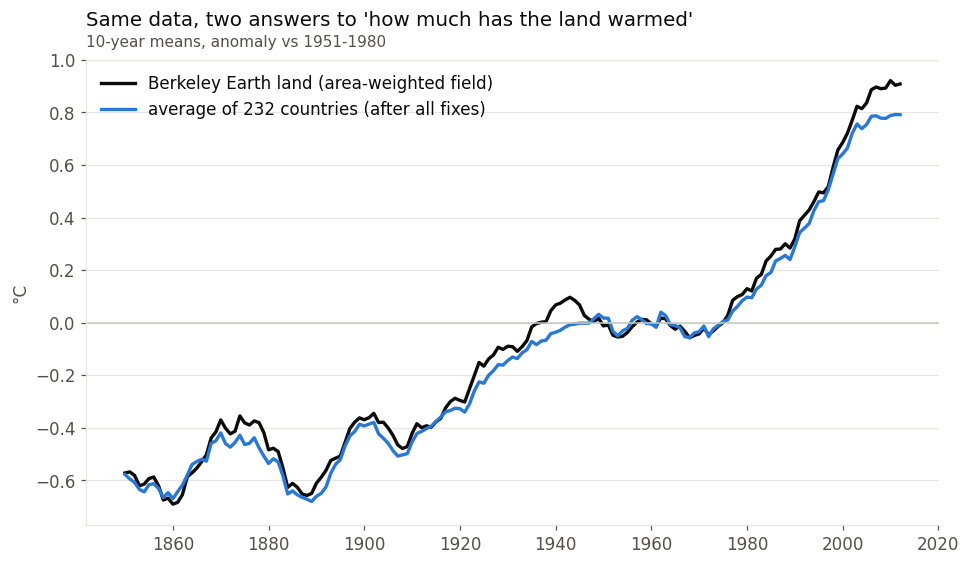

In [15]:
fig, ax = plt.subplots()
for s, colour, label in [(ref, INK, "Berkeley Earth land (area-weighted field)"),
                         (ours, BLUE, "average of 232 countries (after all fixes)")]:
    sm = s.loc[1850:2012].rolling(10, center=True, min_periods=5).mean()
    ax.plot(sm.index, sm.values, color=colour, linewidth=2.2, label=label)
ax.axhline(0, color=FAINT, linewidth=1)
ax.legend(loc="upper left")
style(ax, "Same data, two answers to 'how much has the land warmed'",
      "10-year means, anomaly vs 1951-1980", "°C")
plt.show()

Each country counts once, whatever its size, so Monaco weighs as much as Russia.
Large high-latitude countries, which warmed faster than average, are under-weighted;
that is the most likely reason the blue line runs low. The file
contains no country areas, so the agent could not have fixed this without being asked,
and we didn't ask. **Nobody in the conversation noticed**, including the agent that
had just said its result was "safe".

---
## 4 · The domain layer

Nothing in this section can be found by reading the code.

### 4a · "The world" or "the land"?

In [16]:
print(f"land only    , 2004-2013 vs 1850-1900: {warming(official_land, recent=(2004, 2013)):+.2f} °C")
print(f"land + ocean , 2004-2013 vs 1850-1900: {warming(official_lo, recent=(2004, 2013)):+.2f} °C")

land only    , 2004-2013 vs 1850-1900: +1.42 °C
land + ocean , 2004-2013 vs 1850-1900: +0.84 °C


The prompt asked how much **the world** had warmed. Both agents answered for land only.
Both did write "land" (A: *"global land temperature"*, B: *"land temperatures"*), but
neither said that this is not what was asked. Land warms considerably faster than the
ocean and covers less than a third of the surface. A reader who asked about the world
sees "global" and stops reading.

### 4b · Which Berkeley Earth?

GLM's caveat said land+ocean warming was *"~1.0–1.1 °C over the same period."*
We told it this did not match Berkeley Earth's own series. It then downloaded the
**current** Berkeley Earth files to check.

In [17]:
be_land = read_berkeley_txt(DATA / "reference/berkeley_2025/Complete_TAVG_complete.txt")[0]
be_lo_air, be_lo_water = read_berkeley_txt(DATA / "reference/berkeley_2025/Land_and_Ocean_complete.txt")[:2]
annual = lambda t: t.groupby("year")["anomaly"].mean()

rows = {
    "land, Kaggle release (2017)": warming(official_land, recent=(2004, 2013)),
    "land, current files (2025)": warming(annual(be_land), recent=(2004, 2013)),
    "land+ocean, Kaggle release (2017)": warming(official_lo, recent=(2004, 2013)),
    "land+ocean, 2025, sea-ice as air": warming(annual(be_lo_air), recent=(2004, 2013)),
    "land+ocean, 2025, sea-ice as water": warming(annual(be_lo_water), recent=(2004, 2013)),
}
pd.Series(rows, name="2004-2013 vs 1850-1900 (°C)").round(2).to_frame()

,2004-2013 vs 1850-1900 (°C)
"land, Kaggle release (2017)",1.42
"land, current files (2025)",1.42
"land+ocean, Kaggle release (2017)",0.84
"land+ocean, 2025, sea-ice as air",0.99
"land+ocean, 2025, sea-ice as water",0.88


| who said what | number | |
|---|---|---|
| GLM, first answer | "~1.0–1.1 °C" | |
| us, pushing back | "doesn't match Berkeley Earth" | true for the 2017 release (0.84) |
| GLM, after checking the 2025 files | "0.99" and "0.93" | 0.99 is right; **0.93 is not (0.88)** |

The same name, *"Berkeley Earth land+ocean"*, gives 0.84 or 0.99 depending on the
release and on how sea ice is treated. **A number without a version and a variant
cannot be checked.**

### 4c · When does this data stop?

In [18]:
lo = annual(be_lo_air)
print("our file ends          :", d["dt"].max().date())
print("current file ends      :", f"{be_lo_air['year'].max()}-{be_lo_air['month'].iloc[-1]:02d}")
print(f"land+ocean 2003-2012   : {warming(lo):+.2f} °C vs 1850-1900")
print(f"land+ocean 2015-2024   : {warming(lo, recent=(2015, 2024)):+.2f} °C")
print(f"land+ocean 2024 alone  : {lo.loc[2024] - lo.loc[1850:1900].mean():+.2f} °C")
print("ten warmest years      :", sorted(lo.sort_values().index[-10:]))

our file ends          : 2013-09-01
current file ends      : 2024-12
land+ocean 2003-2012   : +0.98 °C vs 1850-1900
land+ocean 2015-2024   : +1.33 °C
land+ocean 2024 alone  : +1.62 °C
ten warmest years      : [2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


Both agents wrote their conclusion in the present tense: *"has risen"*, *"the last
decade"*. **Their "last decade" ended more than ten years ago.** In the current
record, the ten warmest years are all after our file stops.

---
## 5 · The honest chart

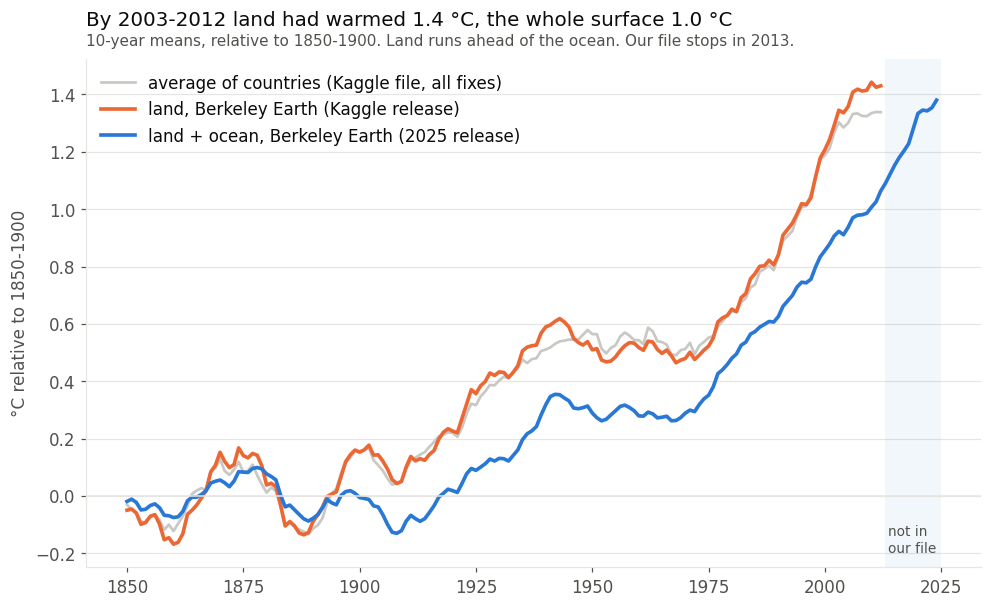

In [19]:
land_rel = official_land - official_land.loc[1850:1900].mean()
ours_rel = fixed - fixed.loc[1850:1900].mean()
lo_rel = lo - lo.loc[1850:1900].mean()

fig, ax = plt.subplots(figsize=(10.5, 6))
for s, colour, width, label in [
        (ours_rel.loc[1850:2012], FAINT, 1.8, "average of countries (Kaggle file, all fixes)"),
        (land_rel.loc[1850:2012], ORANGE, 2.4, "land, Berkeley Earth (Kaggle release)"),
        (lo_rel.loc[1850:2024], BLUE, 2.4, "land + ocean, Berkeley Earth (2025 release)")]:
    sm = s.rolling(10, center=True, min_periods=5).mean()
    ax.plot(sm.index, sm.values, color=colour, linewidth=width, label=label)
ax.axhline(0, color=GRID, linewidth=1)
ax.axvspan(2013, 2024.9, color=BLUE, alpha=0.06, linewidth=0)
ax.text(2013.5, 0.03, "not in\nour file", fontsize=9, color=MUTED, transform=ax.get_xaxis_transform())
ax.legend(loc="upper left")
style(ax, f"By 2003-2012 land had warmed {warming(land_rel):.1f} °C, the whole surface {warming(lo_rel):.1f} °C",
      "10-year means, relative to 1850-1900. Land runs ahead of the ocean. Our file stops in 2013.",
      "°C relative to 1850-1900")
plt.show()

---
## 6 · What actually went wrong

| | what happened | caught by | could a better prompt fix it? |
|---|---|---|---|
| 1 | 14.69 °C: a European November vs nine months of the world | anyone here | yes |
| 2 | coverage grows 50 → 242 countries | anyone who counts | yes, if you know to ask |
| 3 | fake 2013 spike from one annual baseline | someone who knows anomalies | yes, if you know to ask |
| 4 | continents counted as countries | anyone who looks | yes |
| 5 | a **made-up explanation** for why the number changed | someone who checks | **no** |
| 6 | Monaco weighs as much as Russia | someone who knows the method | only if you knew |
| 7 | asked about the world, answered for land without saying so; land+ocean is ~40% less | **someone in the field** | only if you knew |
| 8 | the reference number depends on the dataset version | **someone in the field** | no |
| 9 | "the last decade" ended in 2012 | **someone in the field** | only if you knew |

**The better model did not make fewer mistakes for you to catch. It made more
convincing ones.** Agent A failed in a way you notice in a second. Agent B failed in
ways that need you to know the method, the field, and the data's history, and it told
you the result was safe.

### Before an agent's number goes on your slide

1. **What is a "year" here?** Which months, which countries, stations or grid cells?
2. **Does every time step contain the same things?** `groupby(time)[unit].nunique()`
3. **Anomaly or absolute? Baseline per month?**
4. **What does one row weigh?** A country? An area? A station?
5. **Land, ocean, or both? Which version of the dataset?**
6. **When does the data stop?** Compare with today before writing in the present tense.
7. **When the agent explains *why* a number changed, check the explanation too.**

None of these take more than a minute. All of them need you to know your data.